In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
%cd /content/drive/MyDrive
!git clone https://github.com/bika-a/Pro-Kabaddi-League-Analysis.git
%cd Pro-Kabaddi-League-Analysis/data
!ls

/content/drive/MyDrive
Cloning into 'Pro-Kabaddi-League-Analysis'...
remote: Enumerating objects: 15, done.
remote: Counting objects: 100% (15/15), done.
remote: Compressing objects: 100% (14/14), done.
remote: Total 15 (delta 0), reused 15 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (15/15), 231.47 KiB | 6.26 MiB/s, done.
/content/drive/MyDrive/Pro-Kabaddi-League-Analysis/data
ALL_Defensive_Skills_Merged.csv
ALL_Raider_Skills_Merged.csv
AllSeasons_AllTeams_DefenderSuccessRate.csv
AllSeasons_AllTeams_RaiderSuccessRate.csv
all_seasons_player_stats_rounded.csv
PKL_AggregatedTeamStats.csv
pkl_matches_s1_s10.csv
pkl_player_match_points.csv


In [3]:
import pandas as pd
m = pd.read_csv("pkl_matches_s1_s10.csv")
m.info()
print("Duplicates:", m.drop(columns="season").duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1064 entries, 0 to 1063
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   season       1064 non-null   int64 
 1   game_id      1064 non-null   int64 
 2   match_name   1064 non-null   object
 3   match_date   1064 non-null   object
 4   stage        1064 non-null   object
 5   venue        1048 non-null   object
 6   team_1       1064 non-null   object
 7   score_1      1064 non-null   int64 
 8   team_2       1064 non-null   object
 9   score_2      1064 non-null   int64 
 10  winner       1064 non-null   object
 11  margin       1064 non-null   int64 
 12  result_text  1037 non-null   object
dtypes: int64(5), object(8)
memory usage: 108.2+ KB
Duplicates: 0


In [4]:
display(m.head())
print(m.season.value_counts().sort_index())
print(sorted(set(m.team_1) | set(m.team_2)))

,season,game_id,match_name,match_date,stage,venue,team_1,score_1,team_2,score_2,winner,margin,result_text
0,1,1,Match 1,2014-07-26,League,"DOME,NSCI,SVP STADIUM,MUMBAI",U Mumba,45,Jaipur Pink Panthers,31,U Mumba,14,U Mumba beat Jaipur Pink Panthers (45 - 31)
1,1,2,Match 2,2014-07-26,League,"DOME,NSCI,SVP STADIUM,MUMBAI",Dabang Delhi,28,Bengaluru Bulls,47,Bengaluru Bulls,19,Bengaluru Bulls beat Dabang Delhi (47 - 28)
2,1,3,Match 3,2014-07-27,League,"DOME,NSCI,SVP STADIUM,MUMBAI",Bengaluru Bulls,40,Puneri Paltan,37,Bengaluru Bulls,3,Bengaluru Bulls beat Puneri Paltan (40 - 37)
3,1,4,Match 4,2014-07-27,League,"DOME,NSCI,SVP STADIUM,MUMBAI",U Mumba,36,Bengal Warriors,25,U Mumba,11,U Mumba beat Bengal Warriors (36 - 25)
4,1,5,Match 5,2014-07-28,League,"DOME,NSCI,SVP STADIUM,MUMBAI",Puneri Paltan,31,Dabang Delhi,35,Dabang Delhi,4,Dabang Delhi beat Puneri Paltan (35 - 31)


season
1      60
2      60
3      60
4      60
5     138
6     138
7     137
8     137
9     137
10    137
Name: count, dtype: int64
['Bengal Warriors', 'Bengaluru Bulls', 'Dabang Delhi', 'Dabang Delhi K.C.', 'Gujarat Giants', 'Haryana Steelers', 'Jaipur Pink Panthers', 'Patna Pirates', 'Puneri Paltan', 'Tamil Thalaivas', 'Telugu Titans', 'U Mumba', 'U.P. Yoddha', 'U.P. Yoddhas']


In [5]:
import numpy as np

# 1. Team names
team_map = {
    "Dabang Delhi": "Dabang Delhi K.C.",
    "U.P. Yoddhas": "U.P. Yoddha",
}
for col in ["team_1", "team_2", "winner"]:
    m[col] = m[col].str.strip().replace(team_map)

# 2. Dates to real datetime
m["match_date"] = pd.to_datetime(m["match_date"], errors="coerce")

# 3. Ties
m.loc[m.score_1 == m.score_2, "winner"] = "Tie"

# 4. Venue -> city (missing venues become "Unknown")
def venue_to_city(v):
    if pd.isna(v):
        return "Unknown"
    v = v.upper()
    keys = {"NSCI": "Mumbai", "THYAGARAJ": "Delhi",
            "NETAJI": "Kolkata", "WHITEFIELD": "Bengaluru"}
    for k, city in keys.items():
        if k in v:
            return city
    return "Other"

m["city"] = m.venue.apply(venue_to_city)

# ---- Checks ----
teams = sorted(set(m.team_1) | set(m.team_2))
print("Distinct teams:", len(teams), "(expect 12)")
print(teams)
print("NaT dates:", m.match_date.isna().sum(), "(expect 0)")
print(m.city.value_counts())

Distinct teams: 12 (expect 12)
['Bengal Warriors', 'Bengaluru Bulls', 'Dabang Delhi K.C.', 'Gujarat Giants', 'Haryana Steelers', 'Jaipur Pink Panthers', 'Patna Pirates', 'Puneri Paltan', 'Tamil Thalaivas', 'Telugu Titans', 'U Mumba', 'U.P. Yoddha']
NaT dates: 0 (expect 0)
city
Other        670
Bengaluru    137
Mumbai        97
Kolkata       72
Delhi         72
Unknown       16
Name: count, dtype: int64


In [6]:
a = m.assign(team=m.team_1, pf=m.score_1, pa=m.score_2)
b = m.assign(team=m.team_2, pf=m.score_2, pa=m.score_1)
t = pd.concat([a, b], ignore_index=True)
t["result"] = np.where(t.pf > t.pa, "W", np.where(t.pf < t.pa, "L", "T"))

print(t.shape, "(expect 2128 rows = 1064 x 2)")
print(t.result.value_counts())

(2128, 18) (expect 2128 rows = 1064 x 2)
result
W    963
L    963
T    202
Name: count, dtype: int64


In [7]:
# 1. No duplicate matches (date, teams, scores)
dup = m.duplicated(subset=["match_date","team_1","team_2","score_1","score_2"]).sum()

# 2. Winner consistent with scores
expected = np.where(m.score_1 > m.score_2, m.team_1,
           np.where(m.score_2 > m.score_1, m.team_2, "Tie"))
winner_bad = (m.winner != expected).sum()

# 3. Distinct teams
n_teams = len(set(m.team_1) | set(m.team_2))

results = pd.DataFrame({
    "Test": ["No duplicate matches", "Winner matches scores", "12 distinct teams"],
    "Result": [dup, winner_bad, n_teams],
    "Pass condition": [0, 0, 12],
})
results["Pass"] = results.Result == results["Pass condition"]
display(results)

print(m.stage.value_counts())

,Test,Result,Pass condition,Pass
0,No duplicate matches,0,0,True
1,Winner matches scores,0,0,True
2,12 distinct teams,12,12,True


stage
League            1016
Playoffs            18
Semi Final          16
Final               10
Super Playoffs       4
Name: count, dtype: int64


In [8]:
finals = m[m.stage.str.contains("final", case=False)]
print(m.stage.unique())
display(finals[finals.stage.str.lower().str.strip()=="final"]
        [["season","team_1","score_1","team_2","score_2","winner"]])

['League' 'Semi Final' 'Super Playoffs' 'Final' 'Playoffs']


,season,team_1,score_1,team_2,score_2,winner
59,1,Jaipur Pink Panthers,35,U Mumba,24,Jaipur Pink Panthers
119,2,U Mumba,36,Bengaluru Bulls,30,U Mumba
179,3,U Mumba,28,Patna Pirates,31,Patna Pirates
239,4,Patna Pirates,37,Jaipur Pink Panthers,29,Patna Pirates
377,5,Gujarat Giants,38,Patna Pirates,55,Patna Pirates
515,6,Bengaluru Bulls,38,Gujarat Giants,33,Bengaluru Bulls
652,7,Dabang Delhi K.C.,34,Bengal Warriors,39,Bengal Warriors
789,8,Patna Pirates,36,Dabang Delhi K.C.,37,Dabang Delhi K.C.
926,9,Jaipur Pink Panthers,33,Puneri Paltan,29,Jaipur Pink Panthers
1063,10,Puneri Paltan,28,Haryana Steelers,25,Puneri Paltan


In [9]:
p = pd.read_csv("pkl_player_match_points.csv")
p["team"] = p.team.str.strip().replace(team_map)

p.info()
print("Missing player_role:", round(p.player_role.isna().mean()*100, 1), "% (expect about 35%)")

# Test: player points per team-match <= team score
pt = p.groupby(["season","game_id","team"], as_index=False).points.sum()
chk = pt.merge(t[["season","game_id","team","pf"]],
               on=["season","game_id","team"], how="left")
chk["ok"] = chk.points <= chk.pf

print("Team-matches checked:", len(chk), "(expect 2094)")
print("Unmatched to match table:", chk.pf.isna().sum(), "(expect 0)")
print("Passed:", chk.ok.sum(), "(expect 2092)")
display(chk[~chk.ok])   # the 2 exceptions to inspect

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13737 entries, 0 to 13736
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   season       13737 non-null  int64 
 1   game_id      13737 non-null  int64 
 2   match_date   13737 non-null  object
 3   team         13737 non-null  object
 4   player_id    13737 non-null  int64 
 5   player_name  13737 non-null  object
 6   player_role  8966 non-null   object
 7   points       13737 non-null  int64 
dtypes: int64(4), object(4)
memory usage: 858.7+ KB
Missing player_role: 34.7 % (expect about 35%)
Team-matches checked: 2094 (expect 2094)
Unmatched to match table: 0 (expect 0)
Passed: 2092 (expect 2092)


,season,game_id,team,points,pf,ok
344,3,174,Bengal Warriors,27,26,False
1194,7,1768,Haryana Steelers,52,32,False


In [10]:
ag = pd.read_csv("PKL_AggregatedTeamStats.csv")
print(ag.shape); print(ag.columns.tolist()); print(ag.season.unique())

rs = pd.read_csv("AllSeasons_AllTeams_RaiderSuccessRate.csv")
ds = pd.read_csv("AllSeasons_AllTeams_DefenderSuccessRate.csv")
display(rs.head(3)); display(ds.head(3))

ps = pd.read_csv("all_seasons_player_stats_rounded.csv")
print(ps.columns.tolist())

(116, 56)
['season', 'team_id', 'team_name', 'matches_played', 'team-average-raid-points_rank', 'team-avg-points-scored_rank', 'team-all-outs-conceded_rank', 'team-successful-tackle-percent_rank', 'team-super-raid_rank', 'team-raid_rank', 'team-successful-raid-percent_rank', 'team-dod-raid-points_rank', 'team-super-tackles_rank', 'team-raid-points_rank', 'team-successful-raids_rank', 'team-total-points-conceded_rank', 'team-tackle-points_rank', 'team-total-points_rank', 'team-successful-tackles-per-match_rank', 'team-all-outs-inflicted_rank', 'team-average-tackle-points_rank', 'team-successful-tackles_rank', 'team-all-outs-conceded_value', 'team-successful-tackle-percent_value', 'team-super-raid_value', 'team-raid_value', 'team-successful-raid-percent_value', 'team-dod-raid-points_value', 'team-super-tackles_value', 'Total_touch_points_value', 'Total_bonus_points_value', 'team-raid-points_value', 'team-successful-raids_value', 'team-total-points-conceded_value', 'team-tackle-points_val

,Unique_ID,team_id,team,season,player-id,player-id-clean,Raider Name,Total Raids,Successful Raids,Raider Success Rate,Unnamed: 10,Unnamed: 11,Unnamed: 12
0,team_id_7|Season5|Deepak Hooda,7,Puneri Paltan,5,41.0,41,Deepak Hooda,360,13200%,37%,NaN,1.0,Bengaluru Bulls
1,team_id_7|Season5|Rajesh Mondal,7,Puneri Paltan,5,85.0,85,Rajesh Mondal,269,7900%,29%,NaN,2.0,Dabang Delhi
2,team_id_7|Season5|Sandeep Narwal,7,Puneri Paltan,5,142.0,142,Sandeep Narwal,117,3000%,26%,NaN,3.0,Jaipur Pink Panthers


,Unique_ID,season,team_id,Team,player_id_copy_backup,Defender Name,Total Tackles,Successful Tackles,Defender Success rate,Unnamed: 9,Unnamed: 10,Unnamed: 11,Unnamed: 12,Unnamed: 13,Unnamed: 14,Unnamed: 15,Unnamed: 16,Unnamed: 17
0,team_id_4|5|Surjeet Singh,5,4,Bengal Warriors,322,Surjeet Singh,142,72,51%,NaN,Maninder Singh,143.0,NaN,NaN,NaN,NaN,Bengaluru Bulls,1.0
1,team_id_4|5|Ran Singh,5,4,Bengal Warriors,160,Ran Singh,103,49,48%,NaN,Jang Kun Lee,12.0,NaN,NaN,NaN,NaN,Dabang Delhi,2.0
2,team_id_4|5|Shrikant Tewthia,5,4,Bengal Warriors,107,Shrikant Tewthia,91,31,34%,NaN,Deepak Narwal,211.0,NaN,NaN,NaN,NaN,Jaipur Pink Panthers,3.0


['Unique_ID', 'season', 'player_id', 'player_id_clean', 'player_name', 'player_matches_played', 'player_position_id', 'player_position_name', 'player_team_name', 'team_id', 'team_full_name', 'player-super-tackles_rank', 'player-raid-points_rank', 'player-super-raids_rank', 'player-high-5s_rank', 'player-tackle-points_rank', 'player-avg-tackle-points_rank', 'player-dod-raid-points_rank', 'player-total-points_rank', 'player-successful-tackles_rank', 'player-successful-raids_rank', 'super-10s_rank', 'player-super-tackles_value', 'player-raid-points_value', 'player-super-raids_value', 'player-high-5s_value', 'player-tackle-points_value', 'player-avg-tackle-points_value', 'player-dod-raid-points_value', 'player-total-points_value', 'player-successful-tackles_value', 'player-successful-raids_value', 'super-10s_value', 'player-super-tackles_points_per_match', 'player-raid-points_points_per_match', 'player-super-raids_points_per_match', 'high-5s_points_per_match', 'player-tackle-points_points_

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")

,avg_total,avg_margin,tie_pct,close_pct
season,,,,
1,68.2,8.3,10.0,36.7
2,60.4,8.2,6.7,30.0
3,60.1,9.4,6.7,23.3
4,59.1,6.5,8.3,38.3
5,64.0,7.3,11.6,39.1
6,66.5,7.8,10.1,27.5
7,67.6,7.9,9.5,37.2
8,68.3,7.7,11.7,37.2
9,72.0,8.3,8.8,32.8


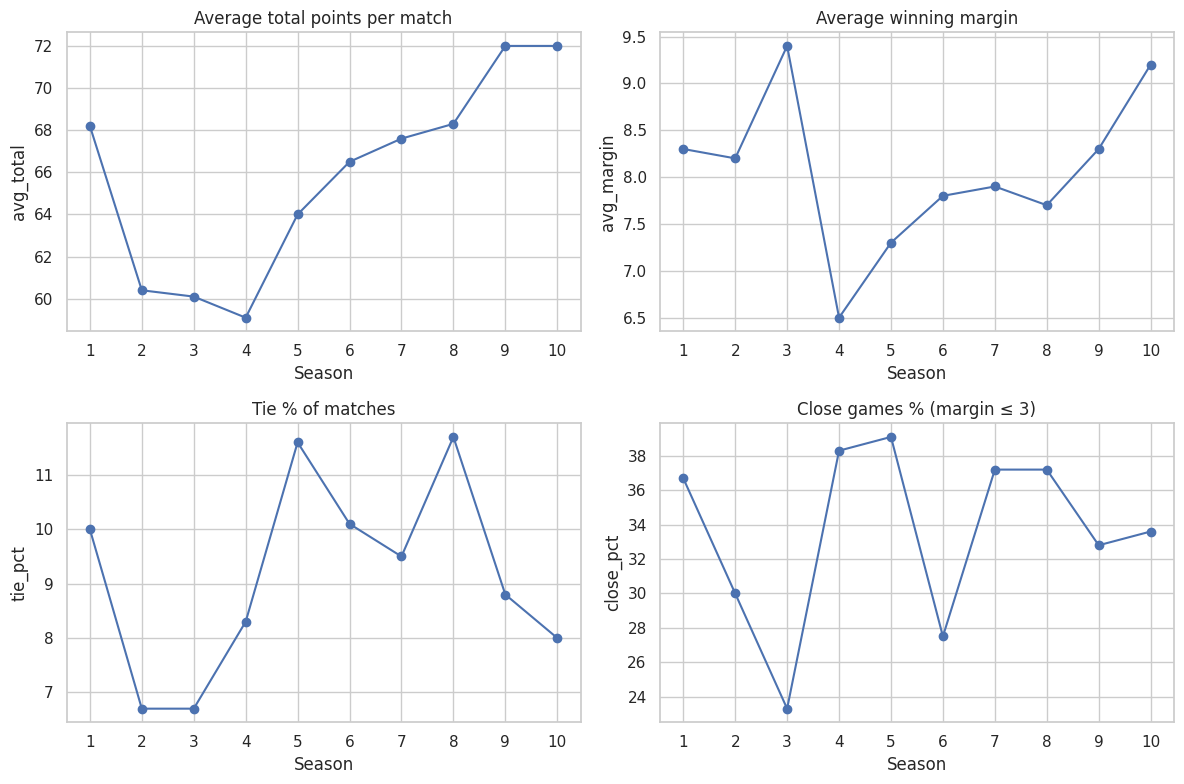

Overall close games %: 34.0 (README: about 34)
Total ties: 101 (README: 101)


In [13]:
m["total"] = m.score_1 + m.score_2
m["tie"] = m.winner == "Tie"
m["close"] = m.margin <= 3

season_tbl = m.groupby("season").agg(
    avg_total=("total", "mean"),
    avg_margin=("margin", "mean"),
    tie_pct=("tie", lambda x: x.mean() * 100),
    close_pct=("close", lambda x: x.mean() * 100),
).round(1)
display(season_tbl)

fig, ax = plt.subplots(2, 2, figsize=(12, 8))
for a, col, title in zip(
    ax.ravel(),
    ["avg_total", "avg_margin", "tie_pct", "close_pct"],
    ["Average total points per match", "Average winning margin",
     "Tie % of matches", "Close games % (margin ≤ 3)"]):
    a.plot(season_tbl.index, season_tbl[col], marker="o")
    a.set_title(title); a.set_xlabel("Season"); a.set_ylabel(col)
    a.set_xticks(range(1, 11))
plt.tight_layout(); plt.show()

print("Overall close games %:", round(m.close.mean() * 100, 1), "(README: about 34)")
print("Total ties:", m.tie.sum(), "(README: 101)")

In [14]:
early = m[m.season <= 4].total
late = m[m.season > 4].total
print(round(early.mean(), 1), round(late.mean(), 1))
print(stats.ttest_ind(early, late, equal_var=False))

61.9 68.4
TtestResult(statistic=np.float64(-8.56656777743215), pvalue=np.float64(1.9508824281759486e-16), df=np.float64(427.77730197744734))


result,L,T,W,matches,win_pct
team,,,,,
U Mumba,78,13,106,197,53.8
Gujarat Giants,53,13,73,139,52.5
Patna Pirates,77,20,107,204,52.5
Jaipur Pink Panthers,81,17,97,195,49.7
Haryana Steelers,57,13,67,137,48.9
Puneri Paltan,86,17,96,199,48.2
Bengaluru Bulls,93,13,94,200,47.0
Bengal Warriors,87,22,86,195,44.1
Dabang Delhi K.C.,93,19,84,196,42.9


,mean,std
team,,
Tamil Thalaivas,28.9,10.0
Haryana Steelers,48.5,12.1
U.P. Yoddha,41.2,13.8
Bengal Warriors,42.2,14.0
Bengaluru Bulls,45.6,15.1
Patna Pirates,53.2,15.2
Gujarat Giants,51.9,15.7
Jaipur Pink Panthers,49.3,17.6
U Mumba,55.3,18.3


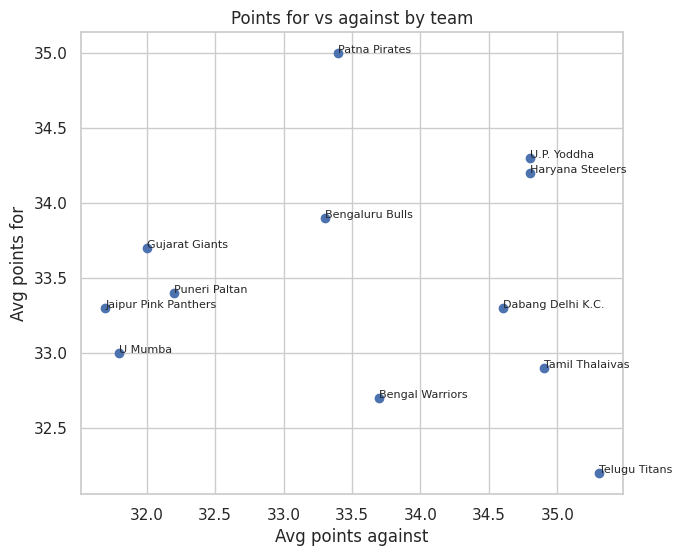

In [15]:
# All-time record and win %
rec = t.groupby("team").result.value_counts().unstack(fill_value=0)
rec["matches"] = rec[["W", "L", "T"]].sum(axis=1)
rec["win_pct"] = (rec.W / rec.matches * 100).round(1)
display(rec.sort_values("win_pct", ascending=False))

# Season win % per team, then consistency (std across seasons)
ts = (t.groupby(["season", "team"]).result
        .apply(lambda x: (x == "W").mean() * 100)
        .rename("win_pct").reset_index())
cons = ts.groupby("team").win_pct.agg(["mean", "std"]).round(1)
display(cons.sort_values("std"))

# Points for vs against
pfa = t.groupby("team")[["pf", "pa"]].mean().round(1)
plt.figure(figsize=(7, 6))
plt.scatter(pfa.pa, pfa.pf)
for name, r in pfa.iterrows():
    plt.annotate(name, (r.pa, r.pf), fontsize=8)
plt.xlabel("Avg points against"); plt.ylabel("Avg points for")
plt.title("Points for vs against by team"); plt.show()

In [16]:
finals = m[m.stage.str.strip().str.lower() == "final"].sort_values("season")
display(finals[["season", "team_1", "score_1", "team_2", "score_2", "winner"]])
print("Finals found:", len(finals), "(expect 10)")

,season,team_1,score_1,team_2,score_2,winner
59,1,Jaipur Pink Panthers,35,U Mumba,24,Jaipur Pink Panthers
119,2,U Mumba,36,Bengaluru Bulls,30,U Mumba
179,3,U Mumba,28,Patna Pirates,31,Patna Pirates
239,4,Patna Pirates,37,Jaipur Pink Panthers,29,Patna Pirates
377,5,Gujarat Giants,38,Patna Pirates,55,Patna Pirates
515,6,Bengaluru Bulls,38,Gujarat Giants,33,Bengaluru Bulls
652,7,Dabang Delhi K.C.,34,Bengal Warriors,39,Bengal Warriors
789,8,Patna Pirates,36,Dabang Delhi K.C.,37,Dabang Delhi K.C.
926,9,Jaipur Pink Panthers,33,Puneri Paltan,29,Jaipur Pink Panthers
1063,10,Puneri Paltan,28,Haryana Steelers,25,Puneri Paltan


Finals found: 10 (expect 10)


,player,points
player_id,,
197,Pardeep Narwal,1236
143,Maninder Singh,1021
81,Rahul Chaudhari,953
41,Deepak Niwas Hooda,872
318,Pawan Kumar Sehrawat,821
2296,Naveen Kumar,819
757,Sachin,721
26,Ajay Thakur,717
326,Rohit Kumar,684


,player,super_10s
player_id,,
197,Pardeep Narwal,65
2296,Naveen Kumar,53
143,Maninder Singh,53
81,Rahul Chaudhari,46
318,Pawan Kumar Sehrawat,40
2024,Arjun Deshwal,34
757,Sachin,34
41,Deepak Niwas Hooda,31
26,Ajay Thakur,27


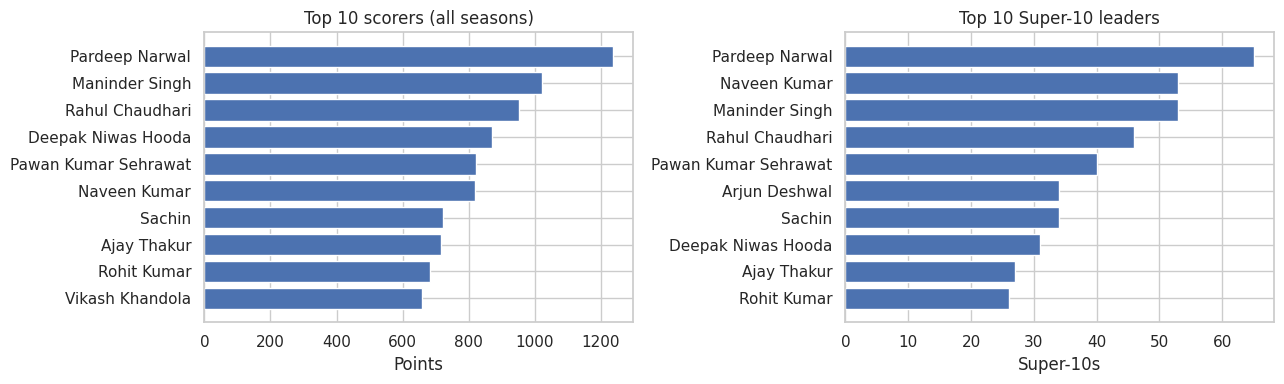

In [17]:
names = p.drop_duplicates("player_id").set_index("player_id").player_name

# Top scorers of all time (grouped by player_id, not name)
tot = p.groupby("player_id").points.sum().sort_values(ascending=False).head(10)
top = tot.to_frame("points")
top["player"] = names.loc[top.index].values
display(top[["player", "points"]])

# Super-10s (10+ points in a match)
s10 = p[p.points >= 10].groupby("player_id").size().sort_values(ascending=False).head(10)
s10 = s10.to_frame("super_10s")
s10["player"] = names.loc[s10.index].values
display(s10[["player", "super_10s"]])

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].barh(top.player[::-1], top.points[::-1]); ax[0].set_title("Top 10 scorers (all seasons)")
ax[1].barh(s10.player[::-1], s10.super_10s[::-1]); ax[1].set_title("Top 10 Super-10 leaders")
ax[0].set_xlabel("Points"); ax[1].set_xlabel("Super-10s")
plt.tight_layout(); plt.show()

/tmp/ipykernel_918/1440569420.py:3: RuntimeWarning: invalid value encountered in scalar divide
  return s.iloc[:2].sum() / s.sum()


Avg top-2 share of player points: 67.8 %
Avg top-2 share of team score: 44.1 %


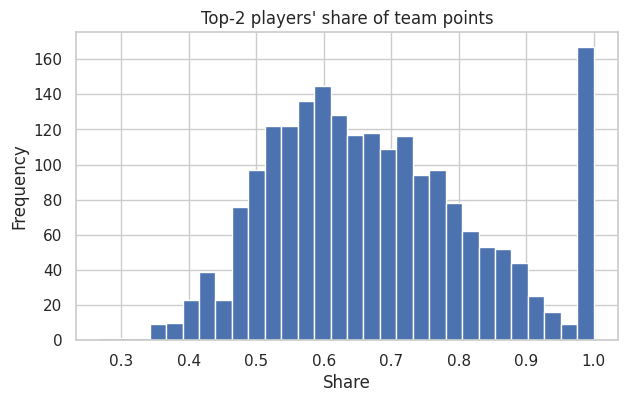

In [18]:
def top2_share(x):
    s = x.sort_values(ascending=False)
    return s.iloc[:2].sum() / s.sum()

share = (p.groupby(["season", "game_id", "team"]).points.apply(top2_share))
print("Avg top-2 share of player points:", round(share.mean() * 100, 1), "%")

# Same, but against the official team score
pt = p.groupby(["season", "game_id", "team"]).points.apply(
    lambda x: x.nlargest(2).sum()).rename("top2").reset_index()
pt = pt.merge(t[["season", "game_id", "team", "pf"]], on=["season", "game_id", "team"])
print("Avg top-2 share of team score:", round((pt.top2 / pt.pf).mean() * 100, 1), "%")

share.plot(kind="hist", bins=30, figsize=(7, 4), title="Top-2 players' share of team points")
plt.xlabel("Share"); plt.show()

city
Other        670
Bengaluru    137
Mumbai        97
Kolkata       72
Delhi         72
Unknown       16
Name: count, dtype: int64
venue
Gachibowli Indoor Stadium, Hyderabad                        71
Shree Kanteerava Indoor Stadium, Bengaluru                  52
Shree Shivchhatrapati Sports Complex,Balewadi, Pune         42
Sawai Mansingh Stadium                                      39
Gachibowli Indoor Stadium                                   29
Patliputra Indoor Stadium                                   28
Kanteerava Indoor Stadium                                   28
The Arena by TransStadia, Ahmedabad                         27
Kanteerava Indoor Stadium, Bengaluru                        23
SHREE SHIV CHHATRAPATI SPORTS COMPLEX, Pune                 22
Patliputra Indoor Stadium, Patna                            22
Sawai Man Singh Indoor Stadium, Jaipur                      22
JAWAHARLAL NEHRU INDOOR STADIUM, Chennai                    21
Shaheed Vijay Singh Pathik Sports Complex,

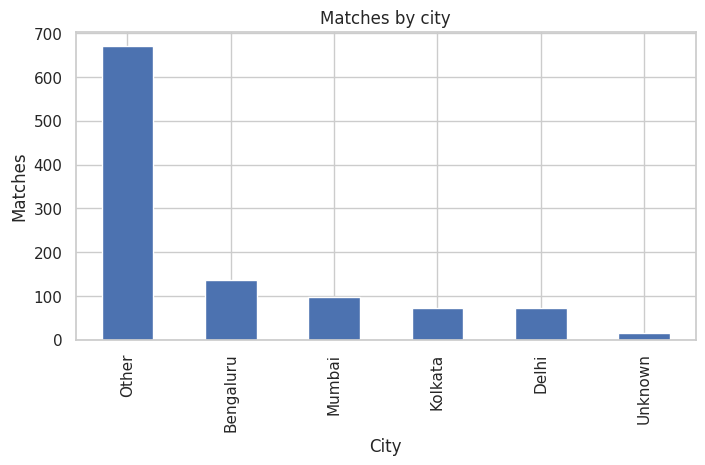

city
Bengaluru    137
Name: count, dtype: int64


In [19]:
print(m.city.value_counts())
print(m[m.city == "Other"].venue.value_counts().head(20))   # venues still unmapped

m.city.value_counts().plot(kind="bar", figsize=(8, 4), title="Matches by city")
plt.xlabel("City"); plt.ylabel("Matches"); plt.show()

# Season 8 bubble
print(m[m.season == 8].city.value_counts())

Shapiro: ShapiroResult(statistic=np.float64(0.9881135047535826), pvalue=np.float64(1.3624710110051146e-07))
Skew: 0.44


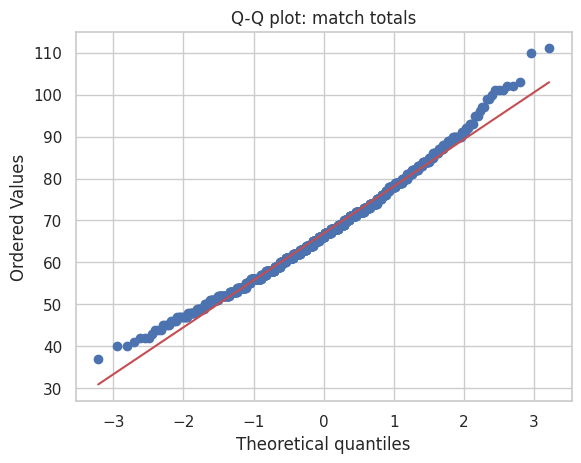

Chi-square p-value: 0.96


In [20]:
# Test 3: normality of match totals
print("Shapiro:", stats.shapiro(m.total))
print("Skew:", round(stats.skew(m.total), 2))
stats.probplot(m.total, dist="norm", plot=plt)
plt.title("Q-Q plot: match totals"); plt.show()

# Test 7: tie rate across seasons
ct = pd.crosstab(m.season, m.tie)
chi2, pval, dof, _ = stats.chi2_contingency(ct)
print("Chi-square p-value:", round(pval, 2))

In [21]:
# How the data defines the home team
!grep -i -n "home" ../DATA_PROFILE.md

# Columns of the remaining files
ag = pd.read_csv("PKL_AggregatedTeamStats.csv")
print("AGG:", ag.shape); print(ag.columns.tolist()); print(ag.season.unique())

rs = pd.read_csv("AllSeasons_AllTeams_RaiderSuccessRate.csv")
ds = pd.read_csv("AllSeasons_AllTeams_DefenderSuccessRate.csv")
print("RAIDER:", rs.columns.tolist()); display(rs.head(3))
print("DEFENDER:", ds.columns.tolist()); display(ds.head(3))

ps = pd.read_csv("all_seasons_player_stats_rounded.csv")
print("PLAYER STATS:", ps.columns.tolist())

AGG: (116, 56)
['season', 'team_id', 'team_name', 'matches_played', 'team-average-raid-points_rank', 'team-avg-points-scored_rank', 'team-all-outs-conceded_rank', 'team-successful-tackle-percent_rank', 'team-super-raid_rank', 'team-raid_rank', 'team-successful-raid-percent_rank', 'team-dod-raid-points_rank', 'team-super-tackles_rank', 'team-raid-points_rank', 'team-successful-raids_rank', 'team-total-points-conceded_rank', 'team-tackle-points_rank', 'team-total-points_rank', 'team-successful-tackles-per-match_rank', 'team-all-outs-inflicted_rank', 'team-average-tackle-points_rank', 'team-successful-tackles_rank', 'team-all-outs-conceded_value', 'team-successful-tackle-percent_value', 'team-super-raid_value', 'team-raid_value', 'team-successful-raid-percent_value', 'team-dod-raid-points_value', 'team-super-tackles_value', 'Total_touch_points_value', 'Total_bonus_points_value', 'team-raid-points_value', 'team-successful-raids_value', 'team-total-points-conceded_value', 'team-tackle-point

,Unique_ID,team_id,team,season,player-id,player-id-clean,Raider Name,Total Raids,Successful Raids,Raider Success Rate,Unnamed: 10,Unnamed: 11,Unnamed: 12
0,team_id_7|Season5|Deepak Hooda,7,Puneri Paltan,5,41.0,41,Deepak Hooda,360,13200%,37%,NaN,1.0,Bengaluru Bulls
1,team_id_7|Season5|Rajesh Mondal,7,Puneri Paltan,5,85.0,85,Rajesh Mondal,269,7900%,29%,NaN,2.0,Dabang Delhi
2,team_id_7|Season5|Sandeep Narwal,7,Puneri Paltan,5,142.0,142,Sandeep Narwal,117,3000%,26%,NaN,3.0,Jaipur Pink Panthers


DEFENDER: ['Unique_ID', 'season', 'team_id', 'Team', 'player_id_copy_backup', 'Defender Name', 'Total Tackles', 'Successful Tackles', 'Defender Success rate', 'Unnamed: 9', 'Unnamed: 10', 'Unnamed: 11', 'Unnamed: 12', 'Unnamed: 13', 'Unnamed: 14', 'Unnamed: 15', 'Unnamed: 16', 'Unnamed: 17']


,Unique_ID,season,team_id,Team,player_id_copy_backup,Defender Name,Total Tackles,Successful Tackles,Defender Success rate,Unnamed: 9,Unnamed: 10,Unnamed: 11,Unnamed: 12,Unnamed: 13,Unnamed: 14,Unnamed: 15,Unnamed: 16,Unnamed: 17
0,team_id_4|5|Surjeet Singh,5,4,Bengal Warriors,322,Surjeet Singh,142,72,51%,NaN,Maninder Singh,143.0,NaN,NaN,NaN,NaN,Bengaluru Bulls,1.0
1,team_id_4|5|Ran Singh,5,4,Bengal Warriors,160,Ran Singh,103,49,48%,NaN,Jang Kun Lee,12.0,NaN,NaN,NaN,NaN,Dabang Delhi,2.0
2,team_id_4|5|Shrikant Tewthia,5,4,Bengal Warriors,107,Shrikant Tewthia,91,31,34%,NaN,Deepak Narwal,211.0,NaN,NaN,NaN,NaN,Jaipur Pink Panthers,3.0


PLAYER STATS: ['Unique_ID', 'season', 'player_id', 'player_id_clean', 'player_name', 'player_matches_played', 'player_position_id', 'player_position_name', 'player_team_name', 'team_id', 'team_full_name', 'player-super-tackles_rank', 'player-raid-points_rank', 'player-super-raids_rank', 'player-high-5s_rank', 'player-tackle-points_rank', 'player-avg-tackle-points_rank', 'player-dod-raid-points_rank', 'player-total-points_rank', 'player-successful-tackles_rank', 'player-successful-raids_rank', 'super-10s_rank', 'player-super-tackles_value', 'player-raid-points_value', 'player-super-raids_value', 'player-high-5s_value', 'player-tackle-points_value', 'player-avg-tackle-points_value', 'player-dod-raid-points_value', 'player-total-points_value', 'player-successful-tackles_value', 'player-successful-raids_value', 'super-10s_value', 'player-super-tackles_points_per_match', 'player-raid-points_points_per_match', 'player-super-raids_points_per_match', 'high-5s_points_per_match', 'player-tackle-

AGG rows: 104 (expect 104)
            Raider Name  Total Raids   succ  rate
0          Deepak Hooda          360  132.0  36.7
1         Rajesh Mondal          269   79.0  29.4
2        Sandeep Narwal          117   30.0  25.6
3                  Monu           77   16.0  20.8
4  Rohit Kumar Choudary           46   10.0  21.7
Max raider rate: 100.0 (should be 100 or less)


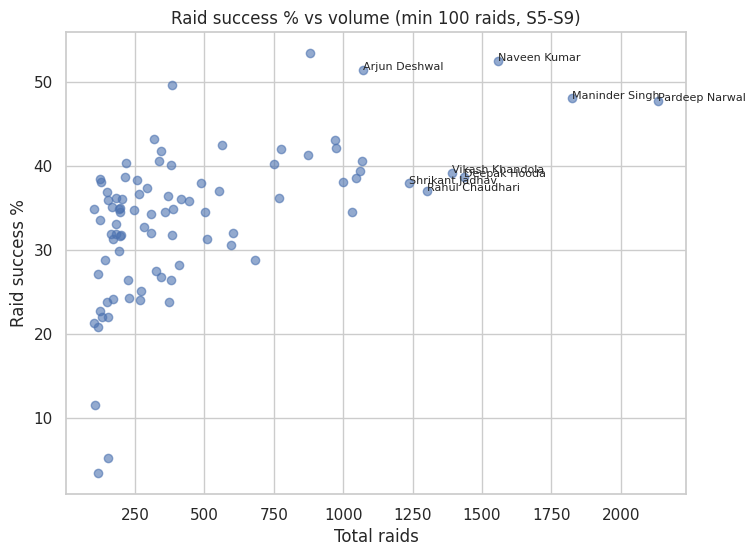

In [27]:
# Item 7: aggregated team stats
ag = ag[ag.season.astype(str) != "all"].copy()
ag["season"] = ag.season.astype(int)
print("AGG rows:", len(ag), "(expect 104)")

# Item 8: success-rate files
rs = rs.loc[:, ~rs.columns.str.startswith("Unnamed")].copy()
ds = ds.loc[:, ~ds.columns.str.startswith("Unnamed")].copy()

# Raiders: "Successful Raids" is corrupted (13200% should be 132)
s = rs["Successful Raids"].astype(str)
v = pd.to_numeric(s.str.rstrip("%"), errors="coerce")
rs["succ"] = np.where(s.str.contains("%"), v / 100, v)
rs["rate"] = (rs.succ / rs["Total Raids"] * 100).round(1)

# Defenders: strip % if present, recompute rate
ds["succ"] = pd.to_numeric(ds["Successful Tackles"].astype(str).str.rstrip("%"), errors="coerce")
ds["rate"] = (ds.succ / ds["Total Tackles"] * 100).round(1)

print(rs[["Raider Name", "Total Raids", "succ", "rate"]].head())
print("Max raider rate:", rs.rate.max(), "(should be 100 or less)")

# Raid success % vs volume (min 100 raids), excluding unknown raiders (id = -1)
rs_known = rs[rs["player-id-clean"] != -1]
g = rs_known.groupby("player-id-clean").agg(
        name=("Raider Name", "first"),
        total=("Total Raids", "sum"),
        succ=("succ", "sum"))
g["rate"] = g.succ / g.total * 100
g = g[g.total >= 100]

plt.figure(figsize=(8, 6))
plt.scatter(g.total, g.rate, alpha=0.6)
for _, r in g.nlargest(8, "total").iterrows():
    plt.annotate(r["name"], (r.total, r.rate), fontsize=8)
plt.xlabel("Total raids"); plt.ylabel("Raid success %")
plt.title("Raid success % vs volume (min 100 raids, S5-S9)")
plt.show()

In [33]:
role_map = (ps.dropna(subset=["player_id_clean"])
              .assign(pid=lambda d: d.player_id_clean.astype(int))
              .groupby("pid").player_position_name
              .agg(lambda x: x.mode().iloc[0] if x.notna().any() else np.nan))

print("Blank roles before:", p.player_role.isna().sum(), f"({p.player_role.isna().mean()*100:.1f}%)")
p["player_role"] = p.player_role.fillna(p.player_id.map(role_map)).fillna("Unknown")
print("Blank roles after:", p.player_role.isna().sum())
print(p.player_role.value_counts())

Blank roles before: 0 (0.0%)
Blank roles after: 0
player_role
Raider                     4553
Defender                   4192
All Rounder                1508
Defender - Left Corner      499
Defender - Right Corner     469
All-Rounder                 453
Defender - Left Cover       415
Defender - Right Cover      388
Unknown                     291
raider                      256
                            178
defender                    167
all-rounder                 156
Right Raider                 38
All-rounder                  35
Left Raider                  34
All- Rounder                 31
Defender-Right Cover         18
Defender-Left Cover          12
Defender - Right corner      12
Defender-Left Corner          8
Left Cover – Defender         5
Raider                        4
Defender, left corner         3
Defender-Right Corner         1
Name: count, dtype: int64


Team-seasons: 104 | unmatched win_pct: 0 (expect 0)
12 teams


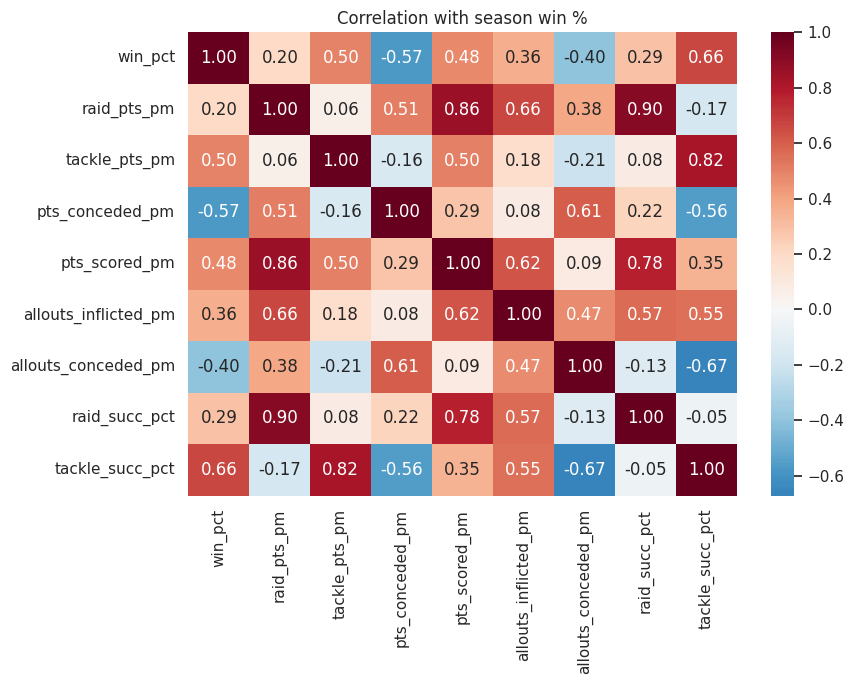

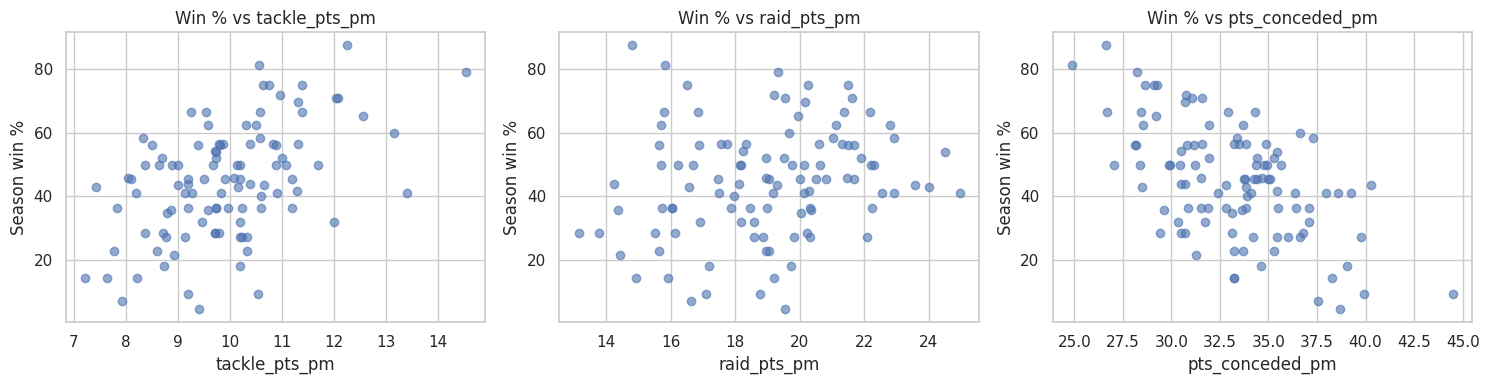

Test 4 tackle points: r = 0.50, p = 8.2e-08
Test 4b tackle success %: r = nan, p = nan
Test 5 raid points: r = 0.20, p = 0.043
Test 5b raid success %: r = nan, p = nan
Test 6 points conceded: r = -0.57, p = 2.7e-10


In [34]:
# helper: numeric columns that may be stored as text with a % sign
def num(s): return pd.to_numeric(s.astype(str).str.rstrip("%"), errors="coerce")

w = ag.copy()
w["team"] = w.team_name.str.strip().replace(team_map)

cols = {
    "raid_pts_pm":    "team-raid-points_per-match",
    "tackle_pts_pm":  "team-tackle-points_per-match",
    "pts_conceded_pm":"team-total-points-conceded_per-match",
    "pts_scored_pm":  "team-total-points_per-match",
    "allouts_inflicted_pm": "team-all-outs-inflicted_per-match",
    "allouts_conceded_pm":  "team-all-outs-conceded_per-match",
    "raid_succ_pct":  "team-successful-raid-percent_value",
    "tackle_succ_pct":"team-successful-tackle-percent_value",
}
for new, old in cols.items():
    w[new] = num(w[old])

# attach season win % (ts was built in Cell 15)
df = w[["season", "team"] + list(cols)].merge(ts, on=["season", "team"], how="left")
print("Team-seasons:", len(df), "| unmatched win_pct:", df.win_pct.isna().sum(), "(expect 0)")
print(df.team.nunique(), "teams")

# Heat map
corr = df[["win_pct"] + list(cols)].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Correlation with season win %"); plt.tight_layout(); plt.show()

# Scatter plots
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, c in zip(ax, ["tackle_pts_pm", "raid_pts_pm", "pts_conceded_pm"]):
    a.scatter(df[c], df.win_pct, alpha=0.6)
    a.set_xlabel(c); a.set_ylabel("Season win %"); a.set_title(f"Win % vs {c}")
plt.tight_layout(); plt.show()

# Tests 4-6 (+ success %)
for label, c in [("4 tackle points", "tackle_pts_pm"), ("4b tackle success %", "tackle_succ_pct"),
                 ("5 raid points", "raid_pts_pm"), ("5b raid success %", "raid_succ_pct"),
                 ("6 points conceded", "pts_conceded_pm")]:
    r, pv = stats.pearsonr(df[c], df.win_pct)
    print(f"Test {label}: r = {r:.2f}, p = {pv:.2g}")

In [28]:
txt = open("../DATA_PROFILE.md").read()
i = txt.find("pkl_matches")
print(txt[i:i+4000])

pkl_matches_s1_s10.csv`

**1,064 rows × 13 columns**

| # | Column | Type | Non-null | Missing % | Unique | Min / Top value | Max / Sample values |
|---|---|---|---|---|---|---|---|
| 1 | `season` | int64 | 1,064 | 0.0 | 10 | 1 | 10 |
| 2 | `game_id` | int64 | 1,064 | 0.0 | 1,064 | 1 | 3165 |
| 3 | `match_name` | str | 1,064 | 0.0 | 151 | Match 1 (10) | Match 1, Match 2, Match 3 |
| 4 | `match_date` | str | 1,064 | 0.0 | 556 | 2021-12-22 (3) | 2014-07-26, 2014-07-27, 2014-07-28 |
| 5 | `stage` | str | 1,064 | 0.0 | 5 | League (1,016) | League, Playoffs, Semi Final, Final |
| 6 | `venue` | str | 1,048 | 1.5 | 43 | Sheraton Grand, Whitefield, Bengaluru (137) | DOME,NSCI,SVP STADIUM,MUMBAI, Netaji Indoor Stadium, Thyagaraj Indoor Stadium |
| 7 | `team_1` | str | 1,064 | 0.0 | 14 | U Mumba (106) | U Mumba, Dabang Delhi, Bengaluru Bulls |
| 8 | `score_1` | int64 | 1,064 | 0.0 | 47 | 15 | 74 |
| 9 | `team_2` | str | 1,064 | 0.0 | 14 | Bengaluru Bulls (108) | Jaipur Pink Panthers, Bengaluru B

In [29]:
dups = p[p.duplicated(keep=False)].sort_values(["game_id", "player_id"])
display(dups)
print(len(p), "rows;", p.duplicated().sum(), "exact duplicates")

,season,game_id,match_date,team,player_id,player_name,player_role,points
9018,7,1768,2019-09-11,Haryana Steelers,42,Dharmaraj Cheralathan,Defender,3
9025,7,1768,2019-09-11,Haryana Steelers,42,Dharmaraj Cheralathan,Defender,3
9016,7,1768,2019-09-11,Haryana Steelers,155,Prashanth Rai,raider,5
9023,7,1768,2019-09-11,Haryana Steelers,155,Prashanth Rai,raider,5
9019,7,1768,2019-09-11,Haryana Steelers,179,Vikas kale,Defender,1
9026,7,1768,2019-09-11,Haryana Steelers,179,Vikas kale,Defender,1
9020,7,1768,2019-09-11,Haryana Steelers,240,Ravi Kumar,Defender,5
9027,7,1768,2019-09-11,Haryana Steelers,240,Ravi Kumar,Defender,5
9032,7,1768,2019-09-11,Jaipur Pink Panthers,293,Nilesh Salunke,Defender,3
9036,7,1768,2019-09-11,Jaipur Pink Panthers,293,Nilesh Salunke,Defender,3


13737 rows; 11 exact duplicates


In [30]:
p_nodup = p.drop_duplicates()
print("Rows with dups:", len(p), "| without:", len(p_nodup))

def narwal(df):
    return df[df.player_name.str.contains("Pardeep Narwal", na=False)].points.sum()
print("Narwal points - with dups:", narwal(p), "| without:", narwal(p_nodup))

Rows with dups: 13737 | without: 13726
Narwal points - with dups: 1236 | without: 1236


In [31]:
p = p.drop_duplicates().reset_index(drop=True)
print("Player rows now:", len(p), "(expect 13726)")

# Re-run the team-score check without the duplicates
pt = p.groupby(["season","game_id","team"], as_index=False).points.sum()
chk = pt.merge(t[["season","game_id","team","pf"]], on=["season","game_id","team"], how="left")
chk["ok"] = chk.points <= chk.pf
print("Checked:", len(chk), "| Passed:", chk.ok.sum())
display(chk[~chk.ok])

Player rows now: 13726 (expect 13726)
Checked: 2094 | Passed: 2093


,season,game_id,team,points,pf,ok
344,3,174,Bengal Warriors,27,26,False


In [32]:
print(m[(m.season==3) & (m.game_id==174)][["match_date","team_1","score_1","team_2","score_2"]])
print(p[(p.season==3) & (p.game_id==174) & (p.team=="Bengal Warriors")][["player_name","player_role","points"]])

    match_date           team_1  score_1           team_2  score_2
172 2016-03-01  Bengal Warriors       26  Bengaluru Bulls       22
            player_name player_role  points
3018      Nilesh Shinde    Defender       7
3019       Jang Kun Lee      Raider       6
3020        Mahesh Goud      Raider       5
3021        Nitin Tomar      Raider       4
3022     Bajirao Hodage    Defender       2
3023       Deepak Kumar    Defender       2
3024  Vijin Thangadurai    Defender       1
3025    Shrikant Jadhav      Raider       0


Team-seasons: 104 (expect 104)
Unmatched win_pct: 0 (expect 0)
Teams: 12 (expect 12)


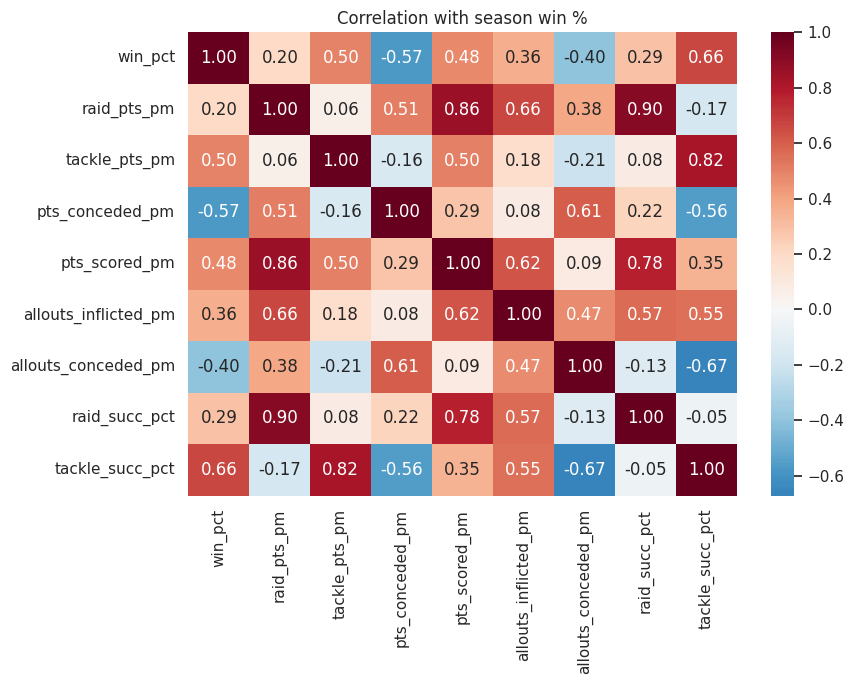

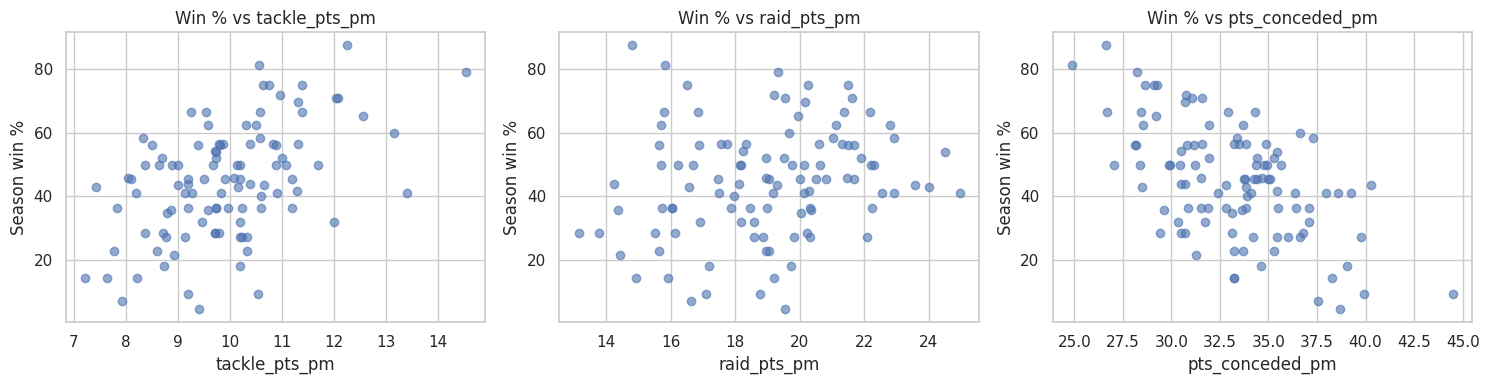

Test 4 tackle points: r = 0.50, p = 8.2e-08
Test 4b tackle success %: r = 0.66, p = 2.6e-07
Test 5 raid points: r = 0.20, p = 0.043
Test 5b raid success %: r = 0.29, p = 0.043
Test 6 points conceded: r = -0.57, p = 2.7e-10


In [35]:
def num(s): return pd.to_numeric(s.astype(str).str.rstrip("%"), errors="coerce")

w = ag.copy()
w["team"] = w.team_name.str.strip().replace(team_map)

cols = {
    "raid_pts_pm":          "team-raid-points_per-match",
    "tackle_pts_pm":        "team-tackle-points_per-match",
    "pts_conceded_pm":      "team-total-points-conceded_per-match",
    "pts_scored_pm":        "team-total-points_per-match",
    "allouts_inflicted_pm": "team-all-outs-inflicted_per-match",
    "allouts_conceded_pm":  "team-all-outs-conceded_per-match",
    "raid_succ_pct":        "team-successful-raid-percent_value",
    "tackle_succ_pct":      "team-successful-tackle-percent_value",
}
for new, old in cols.items():
    w[new] = num(w[old])

df = w[["season", "team"] + list(cols)].merge(ts, on=["season", "team"], how="left")
print("Team-seasons:", len(df), "(expect 104)")
print("Unmatched win_pct:", df.win_pct.isna().sum(), "(expect 0)")
print("Teams:", df.team.nunique(), "(expect 12)")

# Heat map
corr = df[["win_pct"] + list(cols)].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Correlation with season win %")
plt.tight_layout(); plt.show()

# Scatter plots
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, c in zip(ax, ["tackle_pts_pm", "raid_pts_pm", "pts_conceded_pm"]):
    a.scatter(df[c], df.win_pct, alpha=0.6)
    a.set_xlabel(c); a.set_ylabel("Season win %"); a.set_title(f"Win % vs {c}")
plt.tight_layout(); plt.show()

# Pearson tests 4-6
for label, c in [("4 tackle points", "tackle_pts_pm"),
                 ("4b tackle success %", "tackle_succ_pct"),
                 ("5 raid points", "raid_pts_pm"),
                 ("5b raid success %", "raid_succ_pct"),
                 ("6 points conceded", "pts_conceded_pm")]:
    ok = df[[c, "win_pct"]].dropna()
    r, pv = stats.pearsonr(ok[c], ok.win_pct)
    print(f"Test {label}: r = {r:.2f}, p = {pv:.2g}")

In [36]:
print(m.venue.value_counts(dropna=False).to_string())

venue
Sheraton Grand, Whitefield, Bengaluru                       137
Gachibowli Indoor Stadium, Hyderabad                         71
Shree Kanteerava Indoor Stadium, Bengaluru                   52
DOME,NSCI,SVP STADIUM,MUMBAI                                 43
Shree Shivchhatrapati Sports Complex,Balewadi, Pune          42
Netaji Indoor Stadium                                        39
Thyagaraj Indoor Stadium                                     39
Sawai Mansingh Stadium                                       39
Thyagaraj Indoor Stadium, Delhi                              33
Netaji Indoor Stadium, Kolkata                               33
Gachibowli Indoor Stadium                                    29
Patliputra Indoor Stadium                                    28
Kanteerava Indoor Stadium                                    28
The Arena by TransStadia, Ahmedabad                          27
DOME,NSCI,SVP STADIUM,MUMBAI, Mumbai                         25
Kanteerava Indoor Stadium, Bengalu

In [37]:
# 1. Venue -> city (replaces the earlier m["city"]; Season 8 bio-bubble is neutral)
def venue_to_city(v):
    if pd.isna(v): return "Unknown"
    u = v.upper()
    rules = [("WHITEFIELD","Bubble (neutral)"), ("GACHIBOWLI","Hyderabad"), ("BALAYOGI","Hyderabad"),
             ("KANTEERAVA","Bengaluru"), ("NSCI","Mumbai"), ("DOME","Mumbai"),
             ("BALEWADI","Pune"), ("CHHATRAPATI","Pune"), ("NETAJI","Kolkata"),
             ("THYAGARAJ","Delhi"), ("SAWAI","Jaipur"), ("SMS INDOOR","Jaipur"),
             ("PATLIPUTRA","Patna"), ("TRANSSTADIA","Ahmedabad"), ("JAWAHARLAL","Chennai"),
             ("SDAT","Chennai"), ("PATHIK","Noida"), ("NOIDA","Noida"),
             ("RAJIV GANDHI","Kochi"), ("MANKAPUR","Gonda"), ("MOTILAL","Sonepat"),
             ("BABU BANARASI","Lucknow"), ("TAU DEVILAL","Panchkula")]
    for k, c in rules:
        if k in u: return c
    return "Other"

m["city"] = m.venue.apply(venue_to_city)
print(m.city.value_counts())          # "Other" should be 0

# 2. Home cities per team
home_cities = {
    "Bengal Warriors": {"Kolkata"},
    "Bengaluru Bulls": {"Bengaluru"},
    "Dabang Delhi K.C.": {"Delhi"},
    "Gujarat Giants": {"Ahmedabad"},
    "Haryana Steelers": {"Sonepat", "Panchkula"},
    "Jaipur Pink Panthers": {"Jaipur"},
    "Patna Pirates": {"Patna"},
    "Puneri Paltan": {"Pune"},
    "Tamil Thalaivas": {"Chennai"},
    "Telugu Titans": {"Hyderabad"},
    "U Mumba": {"Mumbai"},
    "U.P. Yoddha": {"Noida", "Lucknow", "Gonda"},
}

def home_team(r):
    h1 = r.city in home_cities[r.team_1]
    h2 = r.city in home_cities[r.team_2]
    if h1 and not h2: return r.team_1
    if h2 and not h1: return r.team_2
    return None

m["home_team"] = m.apply(home_team, axis=1)

# 3. Binomial test on decisive games with a home team
dec = m[m.home_team.notna() & (m.winner != "Tie")]
k, n = (dec.winner == dec.home_team).sum(), len(dec)
print("Matches with a home team:", m.home_team.notna().sum())
print("Decisive home games:", n, "(README: 335)")
print("Home wins:", k, f"= {k/n*100:.1f}% (README: 46.3%)")
print(stats.binomtest(k, n, 0.5))

city
Bubble (neutral)    137
Hyderabad           116
Pune                108
Bengaluru           103
Mumbai               97
Kolkata              72
Jaipur               72
Delhi                72
Patna                61
Ahmedabad            49
Chennai              45
Noida                32
Sonepat              22
Panchkula            22
Kochi                18
Unknown              16
Lucknow              11
Gonda                11
Name: count, dtype: int64
Matches with a home team: 373
Decisive home games: 337 (README: 335)
Home wins: 156 = 46.3% (README: 46.3%)
BinomTestResult(k=156, n=337, alternative='two-sided', statistic=0.4629080118694362, pvalue=0.1910117897360713)


In [38]:
# 5A: validation tests
champs = {1:"Jaipur Pink Panthers", 2:"U Mumba", 3:"Patna Pirates", 4:"Patna Pirates",
          5:"Patna Pirates", 6:"Bengaluru Bulls", 7:"Bengal Warriors",
          8:"Dabang Delhi K.C.", 9:"Jaipur Pink Panthers", 10:"Puneri Paltan"}
fin = m[m.stage.str.strip().str.lower() == "final"].set_index("season")
fin_ok = sum(fin.winner.get(s) == c for s, c in champs.items())

exp = np.where(m.score_1 > m.score_2, m.team_1, np.where(m.score_2 > m.score_1, m.team_2, "Tie"))
val = pd.DataFrame([
    ["No duplicated matches", "0 duplicates",
     m.duplicated(subset=["match_date","team_1","team_2","score_1","score_2"]).sum()],
    ["Final winners match champion list", "10/10", f"{fin_ok}/10"],
    ["Winner consistent with scores", "0 mismatches", (m.winner != exp).sum()],
    ["Player points <= team score", "all (README: 2,092 of 2,094)", f"{chk.ok.sum()} of {len(chk)}"],
    ["Distinct teams after mapping", "12", len(set(m.team_1) | set(m.team_2))],
], columns=["Test", "Pass condition", "Result"])
display(val)

#  5B: statistical tests
def pr(c): return stats.pearsonr(df[c], df.win_pct)
tt = stats.ttest_ind(early, late, equal_var=False)
sw = stats.shapiro(m.total)
chi_p = stats.chi2_contingency(pd.crosstab(m.season, m.tie))[1]
rows = [
 ["1", "Mean match total same in S1-4 and S5-10", "Welch t-test", f"{early.mean():.1f} vs {late.mean():.1f}", tt.pvalue],
 ["2", "Home win rate = 50%", "Binomial", f"{k/n*100:.1f}% of {n}", stats.binomtest(k, n, 0.5).pvalue],
 ["3", "Match totals normal", "Shapiro-Wilk", f"skew {stats.skew(m.total):.2f}", sw.pvalue],
 ["4", "Win % unrelated to tackle points", "Pearson", f"r = {pr('tackle_pts_pm')[0]:.2f}", pr('tackle_pts_pm')[1]],
 ["5", "Win % unrelated to raid points", "Pearson", f"r = {pr('raid_pts_pm')[0]:.2f}", pr('raid_pts_pm')[1]],
 ["6", "Win % unrelated to points conceded", "Pearson", f"r = {pr('pts_conceded_pm')[0]:.2f}", pr('pts_conceded_pm')[1]],
 ["7", "Tie rate same across seasons", "Chi-square", "6.7%-11.7% by season", chi_p],
]
tests = pd.DataFrame(rows, columns=["#", "H0", "Test", "Result", "p-value"])
tests["Decision"] = np.where(tests["p-value"] < 0.05, "Reject H0", "Fail to reject H0")
tests["p-value"] = tests["p-value"].apply(lambda x: f"{x:.2g}")
display(tests)

,Test,Pass condition,Result
0,No duplicated matches,0 duplicates,0
1,Final winners match champion list,10/10,10/10
2,Winner consistent with scores,0 mismatches,0
3,Player points <= team score,"all (README: 2,092 of 2,094)",2093 of 2094
4,Distinct teams after mapping,12,12


,#,H0,Test,Result,p-value,Decision
0,1,Mean match total same in S1-4 and S5-10,Welch t-test,61.9 vs 68.4,2e-16,Reject H0
1,2,Home win rate = 50%,Binomial,46.3% of 337,0.19,Fail to reject H0
2,3,Match totals normal,Shapiro-Wilk,skew 0.44,1.4e-07,Reject H0
3,4,Win % unrelated to tackle points,Pearson,r = 0.50,8.2e-08,Reject H0
4,5,Win % unrelated to raid points,Pearson,r = 0.20,0.043,Reject H0
5,6,Win % unrelated to points conceded,Pearson,r = -0.57,2.7e-10,Reject H0
6,7,Tie rate same across seasons,Chi-square,6.7%-11.7% by season,0.96,Fail to reject H0
